# Reto AgroCebada FIRA 2026
## Libreta 04 - Interpretabilidad y Preguntas Guia

> *"¿Que usa el modelo, que tan estable es eso, y que se puede (y no se puede) decir de las preguntas guia?"*

### Seccion del Reporte que alimenta esta libreta
| Seccion del Reporte | Contenido generado aqui |
|---|---|
| **Resultados y Discusion -> Respuestas a las preguntas guia** | Indice mas importante, variable climatica de mayor peso, mejor combinacion de variables (con variabilidad entre folds) |
| **Aplicacion / Dashboard** | Prediccion por parcela, intervalo, parcelas vecinas y distancia, variables que mas influyen |

### Dependencias
Esta libreta usa los artefactos de la **Libreta 02** (`X_integrado_completo.csv`) y de la **Libreta 03** (`resultados_validacion.csv`, `resultados_ablacion.csv`, `predicciones_oof_todos_esquemas.csv`). Ejecuta primero esas libretas.

### Principios de interpretacion
1. **Importancia != causalidad.** SHAP y la permutacion describen como *usa el modelo* las variables, no efectos agronomicos.
2. **Un solo ranking es inestable** con 138 parcelas y variables correlacionadas. Se calcula **por fold** (15 folds de RepeatedKFold) y se reporta media +/- desviacion entre folds y la **frecuencia con que cada variable queda en el top 10**.
3. **Se agrupa** por indice y por bloque, porque SHAP reparte la importancia entre variables colineales (por ejemplo, las cinco metricas fenologicas de un mismo indice).
4. **Se descarta el proxy territorial antes de interpretar:** toda variable relevante se correlaciona con latitud, longitud y elevacion.
5. La pregunta agronomica se contesta con el **HGB agronomico (sin coordenadas)**; el modelo de entrega (con coordenadas) se usa para el dashboard.
6. El clima mensual de ~5 km es casi identico entre parcelas vecinas: su baja importancia **no implica** que el clima no afecte el rendimiento.

In [1]:
# ============================================================
# 1. CONFIGURACION MAESTRA Y ENTORNO (LIBRETA 04)
# ============================================================
!pip install -q geopandas shapely pyproj pyshp scikit-learn shap scipy joblib

import os
import re
import json
import joblib
import warnings
from pathlib import Path
from functools import partial

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from scipy.stats import spearmanr

from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.model_selection import RepeatedKFold, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics.pairwise import haversine_distances
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

EN_COLAB = True  # Cambiar a False si el evaluador lo corre en su PC local (GitHub)

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Reto_AgroCebada_2026')
else:
    BASE = Path(os.getcwd())

CARPETAS = {
    'raw':           BASE / 'data' / 'raw',
    '01_calidad':    BASE / 'data' / '01_calidad',
    '02_fenologia':  BASE / 'data' / '02_fenologia',
    '03_validacion': BASE / 'data' / '03_validacion',
    '04_shap':       BASE / 'data' / '04_shap',
    '05_final':      BASE / 'data' / '05_final',
    'models':        BASE / 'models',
    'artifacts':     BASE / 'artifacts',
    'reports':       BASE / 'reports',
}

for carpeta in CARPETAS.values():
    carpeta.mkdir(parents=True, exist_ok=True)

def guardar_csv(df, nombre, carpeta='raw'):
    ruta = CARPETAS[carpeta] / nombre
    df.to_csv(ruta, index=False, encoding='utf-8-sig')
    print(f"[OK] Guardado: {ruta}")
    return ruta

def cargar_csv(nombre, carpeta='raw', **kwargs):
    ruta = CARPETAS[carpeta] / nombre
    assert ruta.exists(), f"[ERROR] No existe: {ruta}"
    df = pd.read_csv(ruta, **kwargs)
    print(f"[OK] Cargado: {nombre} ({df.shape[0]} filas x {df.shape[1]} cols)")
    return df

def guardar_figura(fig, nombre, carpeta='reports'):
    ruta = CARPETAS[carpeta] / nombre
    fig.savefig(ruta, dpi=200, bbox_inches='tight')
    print(f"[OK] Grafico guardado: {ruta}")
    return ruta

def listar_archivos(carpeta='raw'):
    ruta = CARPETAS[carpeta]
    archivos = sorted(ruta.iterdir()) if ruta.exists() else []
    if not archivos:
        print(f"Carpeta '{carpeta}' vacia")
    else:
        print(f"Carpeta '{carpeta}': {len(archivos)} archivos")
        for a in archivos:
            tamano = a.stat().st_size
            unidad = 'MB' if tamano > 1e6 else 'KB' if tamano > 1e3 else 'B'
            valor = tamano / 1e6 if tamano > 1e6 else tamano / 1e3 if tamano > 1e3 else tamano
            print(f"   - {a.name} ({valor:.1f} {unidad})")
    return archivos

# Semillas y parametros de validacion
SEMILLA = 999
N_SPLITS_RK = 5
N_REPEATS_RK = 3
TAMANO_CELDA_CHIRPS = 0.05

# Constantes de la decision y del modelo final (coinciden con el reporte)
TOLERANCIA_DECISION = 0.02
SEMILLA_HGB_FINAL = 2026
K_VARS = 20
FORZAR_COORDS_HGB_FINAL = True

print("[OK] Configuracion completada (Libreta 04)")
print(f"     Semilla global: {SEMILLA} | shap version: {shap.__version__}")

Mounted at /content/drive
[OK] Configuracion completada (Libreta 04)
     Semilla global: 999 | shap version: 0.52.0


In [2]:
# ============================================================
# 2. CARGA DE DATOS DESDE DRIVE
# ============================================================
print("Cargando artefactos de las Libretas 01 y 02...")

# Matriz integrada de caracteristicas (insumo principal)
X_integrado = cargar_csv('X_integrado_completo.csv', '02_fenologia')

# Variable objetivo
ruta_y_real = CARPETAS['raw'] / 'extraido' / 'DATASET_RETO_AGRO_2026' / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv'
if ruta_y_real.exists():
    y_df = pd.read_csv(ruta_y_real)
    print(f"[OK] Cargado: y_rendimiento real desde {ruta_y_real.name} ({y_df.shape[0]} filas)")
else:
    y_df = cargar_csv('y_rendimiento.csv', '01_calidad')

# Metadatos espaciales (coordenadas + municipio + estado) desde el shapefile
RAW = CARPETAS['raw'] / 'extraido'
shp_files = list(RAW.glob('**/*.shp'))
if not shp_files:
    shp_files = list((CARPETAS['raw'] / 'extraido').glob('*/*.shp'))
assert len(shp_files) >= 1, "No se encontro el shapefile de parcelas"
gdf_parcelas = gpd.read_file(shp_files[0])

# Normalizar columna ID
columnas_id = [c for c in gdf_parcelas.columns if 'ID_POL' in c.upper()]
if columnas_id:
    gdf_parcelas = gdf_parcelas.rename(columns={columnas_id[0]: 'ID_POLIGONO'})
gdf_parcelas['ID_POLIGONO'] = gdf_parcelas['ID_POLIGONO'].astype(str).str.strip()

# Extraer coordenadas de centroides (WGS84)
if gdf_parcelas.crs is None:
    gdf_parcelas = gdf_parcelas.set_crs('EPSG:4326')
gdf_wgs84 = gdf_parcelas.to_crs(epsg=4326)
gdf_parcelas['latitud'] = gdf_wgs84.geometry.centroid.y
gdf_parcelas['longitud'] = gdf_wgs84.geometry.centroid.x

# Detectar columnas de municipio/estado
col_municipio = None
col_estado = None
for c in gdf_parcelas.columns:
    if 'munici' in c.lower():
        col_municipio = c
    if 'estado' in c.lower():
        col_estado = c

print(f"\n   Columna de municipio detectada: {col_municipio}")
print(f"   Columna de estado detectada:    {col_estado}")

# Construir tabla de metadatos espaciales
meta_cols = {
    'ID_POLIGONO': gdf_parcelas['ID_POLIGONO'],
    'latitud': gdf_parcelas['latitud'],
    'longitud': gdf_parcelas['longitud']
}
if col_municipio:
    meta_cols['municipio'] = gdf_parcelas[col_municipio]
if col_estado:
    meta_cols['estado'] = gdf_parcelas[col_estado]
df_meta = pd.DataFrame(meta_cols)

print(f"\n[OK] Metadatos espaciales: {len(df_meta)} parcelas")
print(f"[OK] X_integrado:          {X_integrado.shape[0]} parcelas x {X_integrado.shape[1]} variables")
print(f"[OK] y:                    {len(y_df)} etiquetas")

Cargando artefactos de las Libretas 01 y 02...
[OK] Cargado: X_integrado_completo.csv (197 filas x 188 cols)
[OK] Cargado: y_rendimiento real desde ID_area_rendimiento_70_30_Reto_AgroCebada.csv (197 filas)

   Columna de municipio detectada: Municipio
   Columna de estado detectada:    Estado

[OK] Metadatos espaciales: 197 parcelas
[OK] X_integrado:          197 parcelas x 188 variables
[OK] y:                    197 etiquetas


In [3]:
# ============================================================
# 3. PREPARAR MATRICES DE ENTRENAMIENTO (138) Y PREDICCION (59)
# ============================================================
X_integrado['ID_POLIGONO'] = X_integrado['ID_POLIGONO'].astype(str).str.strip()
y_df['ID_POLIGONO'] = y_df['ID_POLIGONO'].astype(str).str.strip()
df_meta['ID_POLIGONO'] = df_meta['ID_POLIGONO'].astype(str).str.strip()

# IDs de las 59 parcelas a predecir
ids_prediccion = y_df.loc[y_df['RENDIMIENTO_T_HA'].isna(), 'ID_POLIGONO'].tolist()
assert len(ids_prediccion) == 59, f"Se esperaban 59 parcelas sin rendimiento; hay {len(ids_prediccion)}"
df_prediccion = (X_integrado[X_integrado['ID_POLIGONO'].isin(ids_prediccion)]
                 .merge(df_meta, on='ID_POLIGONO', how='left', validate='one_to_one')
                 .reset_index(drop=True))

# Solo se toma el rendimiento de la tabla maestra porque X_integrado ya contiene AREA_HA
y_df = y_df[['ID_POLIGONO', 'RENDIMIENTO_T_HA']].copy()

df_trabajo = y_df.merge(X_integrado, on='ID_POLIGONO', how='inner', validate='one_to_one')
df_trabajo = df_trabajo.merge(df_meta, on='ID_POLIGONO', how='left', validate='one_to_one')
assert 'AREA_HA' in df_trabajo.columns, "AREA_HA no llego a la matriz de trabajo"
df_trabajo = df_trabajo.dropna(subset=['RENDIMIENTO_T_HA']).reset_index(drop=True)
assert len(df_trabajo) == 138, f"Se esperaban 138 parcelas etiquetadas; hay {len(df_trabajo)}"

print(f"Parcelas con rendimiento conocido: {len(df_trabajo)}")
print(f"Rendimiento: media={df_trabajo['RENDIMIENTO_T_HA'].mean():.2f} t/ha, "
      f"std={df_trabajo['RENDIMIENTO_T_HA'].std():.2f} t/ha")

y = df_trabajo['RENDIMIENTO_T_HA'].reset_index(drop=True)
ids = df_trabajo['ID_POLIGONO'].reset_index(drop=True)
coords = df_trabajo[['latitud', 'longitud']].reset_index(drop=True)

# Variables candidatas: todas las numericas que no son metadatos
COLS_META = ['ID_POLIGONO', 'RENDIMIENTO_T_HA', 'latitud', 'longitud', 'municipio', 'estado']
candidatas = [c for c in df_trabajo.columns if c not in COLS_META]
no_numericas = [c for c in candidatas if not pd.api.types.is_numeric_dtype(df_trabajo[c])]
if no_numericas:
    print(f"[AVISO] Columnas no numericas excluidas: {no_numericas}")
columnas_x = [c for c in candidatas if c not in no_numericas]

# Bloques de variables (por prefijo)
bloques = {
    'suelo_termico': [c for c in columnas_x if c.startswith('suelo_termico')],
    'vegetacion':    [c for c in columnas_x if c.startswith('vegetacion')],
    'fenologia':     [c for c in columnas_x if c.startswith('fenologia')],
    'agua':          [c for c in columnas_x if c.startswith('agua')],
    'topografia':    [c for c in columnas_x if c.startswith(('Elevacion', 'Pendiente'))],
    'clima':         [c for c in columnas_x if c.startswith(('PREC_', 'Tmin_', 'Tmax_'))],
    'fisica':        [c for c in columnas_x if c.startswith('fisica__')],
    'area':          [c for c in columnas_x if c == 'AREA_HA'],
}
sin_bloque = [c for c in columnas_x if not any(c in v for v in bloques.values())]

print("\nBloques de variables:")
for nombre, cols in bloques.items():
    print(f"   {nombre:14s}: {len(cols):3d} variables")
print(f"   {'TOTAL':14s}: {len(columnas_x):3d} variables")
if sin_bloque:
    print(f"[AVISO] Variables sin bloque asignado: {sin_bloque}")

assert len(bloques['clima']) == 21, f"El bloque de clima debe tener 21 variables y tiene {len(bloques['clima'])}."
assert len(bloques['area']) == 1, "AREA_HA debe estar exactamente una vez en la matriz."
assert len(columnas_x) == len(set(columnas_x)), "Hay columnas duplicadas en la matriz."

X_full = df_trabajo[columnas_x].reset_index(drop=True)
X_full_clean = X_full
cols_feat_hgb_final = list(X_full.columns)
X_hgb_final = pd.concat([X_full, coords], axis=1)

Parcelas con rendimiento conocido: 138
Rendimiento: media=3.96 t/ha, std=0.85 t/ha

Bloques de variables:
   suelo_termico :   7 variables
   vegetacion    :   9 variables
   fenologia     : 135 variables
   agua          :   3 variables
   topografia    :   2 variables
   clima         :  21 variables
   fisica        :   9 variables
   area          :   1 variables
   TOTAL         : 187 variables


In [4]:
# ============================================================
# 4. CONSTRUCTORES DE MODELOS Y PARTICIONES DE VALIDACION
# ============================================================
PARAMS_HGB = {                      # HGB agronomico (sin coordenadas)
    'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 10,
    'l2_regularization': 10.0, 'random_state': SEMILLA,
}
PARAMS_HGB_FINAL = {                # HGB final (coincide con el reporte)
    'learning_rate': 0.06, 'max_leaf_nodes': 15, 'min_samples_leaf': 5,
    'l2_regularization': 8.0, 'random_state': SEMILLA_HGB_FINAL,
}
PARAMS_KNN = {'n_neighbors': 5, 'weights': 'distance'}
COLS_COORDS = ['latitud', 'longitud']


def construir_modelo(tipo, columnas_x=None):
    """Devuelve un Pipeline sin ajustar. Todo el preprocesamiento vive dentro del pipeline (sin fuga entre folds)."""
    if tipo == 'dummy':
        return Pipeline([('dummy', DummyRegressor(strategy='mean'))])
    if tipo == 'knn':
        return Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(**PARAMS_KNN))])
    if tipo == 'hgb':
        return Pipeline([('hgb', HistGradientBoostingRegressor(**PARAMS_HGB))])
    if tipo == 'hgb_final':
        cols = list(columnas_x)
        k = min(K_VARS, len(cols) + (0 if FORZAR_COORDS_HGB_FINAL else len(COLS_COORDS)))
        seleccion = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc', StandardScaler()),
            ('kbest', SelectKBest(score_func=partial(mutual_info_regression, random_state=SEMILLA), k=k)),
        ])
        if FORZAR_COORDS_HGB_FINAL:
            transformadores = [('coords', 'passthrough', COLS_COORDS), ('sel', seleccion, cols)]
        else:
            transformadores = [('sel', seleccion, cols + COLS_COORDS)]
        return Pipeline([('ct', ColumnTransformer(transformadores)),
                         ('hgb', HistGradientBoostingRegressor(**PARAMS_HGB_FINAL))])
    raise ValueError(f"Tipo de modelo desconocido: {tipo}")


def generar_splits(esquema, n):
    """Lista de (train_idx, test_idx, repeticion, etiqueta_del_fold)."""
    idx = np.arange(n)
    if esquema == 'RepeatedKFold':
        rkf = RepeatedKFold(n_splits=N_SPLITS_RK, n_repeats=N_REPEATS_RK, random_state=SEMILLA)
        return [(tr, te, k // N_SPLITS_RK, f'rep{k // N_SPLITS_RK + 1}_fold{k % N_SPLITS_RK + 1}')
                for k, (tr, te) in enumerate(rkf.split(idx))]
    raise ValueError(f"Esquema desconocido: {esquema}")

print("[OK] Constructores de modelos y particiones listos")
print(f"     HGB final: SelectKBest k={K_VARS}; coordenadas forzadas = {FORZAR_COORDS_HGB_FINAL}")

[OK] Constructores de modelos y particiones listos
     HGB final: SelectKBest k=20; coordenadas forzadas = True


### 1. Importancia por fold: SHAP y permutacion (HGB agronomico, sin coordenadas)

Por cada uno de los 15 folds de RepeatedKFold se ajusta el modelo con el conjunto de entrenamiento y se calcula, **solo sobre el conjunto de validacion del fold**:
- `shap_abs`: media del |SHAP| por variable;
- `perm_mae`: aumento del MAE al permutar la variable (permutacion individual);
- permutacion **por grupo** (todas las columnas del grupo se permutan juntas), que maneja mejor la colinealidad.

In [5]:
# ============================================================
# 5. IMPORTANCIAS POR FOLD (SHAP Y PERMUTACION)
# ============================================================
N_REP_PERM = 5
rng_perm = np.random.default_rng(SEMILLA)
splits_rk = generar_splits('RepeatedKFold', len(y))
cols_modelo = list(X_full.columns)


# ---------- Definicion de grupos ----------
def bloque_de(col):
    for nombre, cols in bloques.items():
        if col in cols:
            return nombre
    return 'otro'

def indice_de(col):
    """Nombre del indice satelital al que pertenece la variable (None si no aplica)."""
    p = col.split('__')
    if col.startswith('fenologia__') and len(p) >= 3:
        return p[1]                                         # p. ej. ndvi, PRO_ndvi
    if col.startswith('vegetacion__') and len(p) >= 3:
        return ('PRO_' if p[1] == 'pro' else '') + p[2]
    if col.startswith(('suelo_termico__', 'agua__')) and len(p) >= 2:
        return p[1]
    return None

def clima_de(col):
    """(variable, mes) para columnas CHIRPS/CHIRTS, p. ej. ('PREC', '04')."""
    if col.startswith(('PREC_', 'Tmin_', 'Tmax_')):
        p = col.split('_')
        return p[0], p[2]
    return None

grupos_def = {'bloque': {}, 'indice': {}, 'clima_variable': {}, 'clima_mes': {}}
for c in cols_modelo:
    grupos_def['bloque'].setdefault(bloque_de(c), []).append(c)
    ind = indice_de(c)
    if ind:
        grupos_def['indice'].setdefault(ind, []).append(c)
    cl = clima_de(c)
    if cl:
        grupos_def['clima_variable'].setdefault(cl[0], []).append(c)
        grupos_def['clima_mes'].setdefault(cl[1], []).append(c)


def shap_valores(pipe, X_tr, X_te):
    """SHAP del HGB ajustado. TreeExplainer; si falla, explicador generico mas lento."""
    modelo = pipe.named_steps['hgb']
    try:
        return np.asarray(shap.TreeExplainer(modelo).shap_values(X_te))
    except Exception as e:
        print(f"   (TreeExplainer no disponible: {type(e).__name__}; se usa el explicador generico)")
        fondo = shap.sample(X_tr, min(50, len(X_tr)), random_state=SEMILLA)
        return np.asarray(shap.Explainer(pipe.predict, fondo)(X_te).values)


def perm_grupo(pipe, X_te, y_te, cols, base_mae):
    deltas = []
    for _ in range(N_REP_PERM):
        Xp = X_te.copy()
        orden = rng_perm.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[orden]
        deltas.append(mean_absolute_error(y_te, pipe.predict(Xp)) - base_mae)
    return float(np.mean(deltas))


filas_var, filas_grp = [], []
for k, (tr, te, rep, etiqueta) in enumerate(splits_rk):
    pipe = construir_modelo('hgb')
    pipe.fit(X_full.iloc[tr], y.iloc[tr])
    X_te, y_te = X_full.iloc[te], y.iloc[te]
    sv = shap_valores(pipe, X_full.iloc[tr], X_te)
    shap_abs = np.abs(sv).mean(axis=0)
    base = mean_absolute_error(y_te, pipe.predict(X_te))
    pi = permutation_importance(pipe, X_te, y_te, scoring='neg_mean_absolute_error',
                                n_repeats=N_REP_PERM, random_state=SEMILLA)
    for j, c in enumerate(cols_modelo):
        filas_var.append({'fold': etiqueta, 'variable': c, 'shap_abs': shap_abs[j], 'perm_mae': pi.importances_mean[j]})
    for tipo, dic in grupos_def.items():
        for g, cols in dic.items():
            idxs = [cols_modelo.index(c) for c in cols]
            filas_grp.append({'fold': etiqueta, 'tipo': tipo, 'grupo': g, 'n_vars': len(cols),
                              'shap_abs_suma': float(shap_abs[idxs].sum()),
                              'perm_grupo_mae': perm_grupo(pipe, X_te, y_te, cols, base)})

df_imp_var = pd.DataFrame(filas_var)
df_imp_grp = pd.DataFrame(filas_grp)
n_folds = len(splits_rk)
print(f"[OK] Importancias calculadas en {n_folds} folds")

# ---------- Resumen por variable ----------
df_imp_var['rank_shap'] = df_imp_var.groupby('fold')['shap_abs'].rank(ascending=False, method='first')
res_var = df_imp_var.groupby('variable').agg(
    shap_media=('shap_abs', 'mean'), shap_sd=('shap_abs', 'std'),
    perm_media=('perm_mae', 'mean'), perm_sd=('perm_mae', 'std'),
    folds_en_top10=('rank_shap', lambda r: int((r <= 10).sum()))).sort_values('shap_media', ascending=False)
res_var['bloque'] = [bloque_de(c) for c in res_var.index]
print(f"\nTop 15 variables por |SHAP| medio (media +/- sd entre folds; 'top10' = folds en que esta entre las 10 primeras de {n_folds}):")
print(res_var.head(15)[['bloque', 'shap_media', 'shap_sd', 'perm_media', 'perm_sd', 'folds_en_top10']].round(4).to_string())

# ---------- Resumen por grupo ----------
res_grp = df_imp_grp.groupby(['tipo', 'grupo']).agg(
    n_vars=('n_vars', 'first'),
    shap_media=('shap_abs_suma', 'mean'), shap_sd=('shap_abs_suma', 'std'),
    perm_media=('perm_grupo_mae', 'mean'), perm_sd=('perm_grupo_mae', 'std')).reset_index()
for tipo in ['bloque', 'indice', 'clima_variable', 'clima_mes']:
    print(f"\nGrupos por {tipo} (ordenados por SHAP agrupado):")
    print(res_grp[res_grp['tipo'] == tipo].sort_values('shap_media', ascending=False).head(10)
          .round(4).to_string(index=False))

guardar_csv(res_var.reset_index(), 'importancia_variables.csv', '04_shap')
guardar_csv(res_grp, 'importancia_grupos.csv', '04_shap')
guardar_csv(df_imp_var.drop(columns='rank_shap'), 'importancia_variables_por_fold.csv', '04_shap')

[OK] Importancias calculadas en 15 folds

Top 15 variables por |SHAP| medio (media +/- sd entre folds; 'top10' = folds en que esta entre las 10 primeras de 15):
                                           bloque  shap_media  shap_sd  perm_media  perm_sd  folds_en_top10
variable                                                                                                   
PREC_2025_05_mean                           clima      0.5765   0.0295      0.4400   0.0584              15
fenologia__srndi__iqr                   fenologia      0.0303   0.0197      0.0024   0.0087              11
Pendiente_INEGI_CEM4_120m_grados_mean  topografia      0.0295   0.0142     -0.0022   0.0062              10
fenologia__dswi4__p90                   fenologia      0.0282   0.0259      0.0047   0.0120               8
fenologia__ndti__iqr                    fenologia      0.0274   0.0092      0.0074   0.0084              13
fenologia__fapar__delta_max             fenologia      0.0246   0.0134      0.0080 

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/04_shap/importancia_variables_por_fold.csv')

In [6]:
# ============================================================
# 6. ¿LAS VARIABLES MAS IMPORTANTES SON PROXIES DE UBICACION?
# Correlacion de Spearman con latitud, longitud y elevacion (138 parcelas).
# ============================================================
col_elev = next((c for c in X_full.columns if c.startswith('Elevacion')), None)
referencias = {'latitud': coords['latitud'], 'longitud': coords['longitud']}
if col_elev:
    referencias['elevacion'] = X_full[col_elev]

filas = []
for var in res_var.head(15).index:
    fila = {'variable': var}
    for nombre, ref in referencias.items():
        mask = X_full[var].notna()
        fila[f'rho_{nombre}'] = spearmanr(X_full.loc[mask, var], ref[mask])[0]
    filas.append(fila)
df_proxy = pd.DataFrame(filas)
rho_cols = [c for c in df_proxy.columns if c.startswith('rho_')]
df_proxy['max_abs_rho'] = df_proxy[rho_cols].abs().max(axis=1)
df_proxy['posible_proxy_territorial'] = df_proxy['max_abs_rho'] >= 0.5

print("Correlacion (Spearman) de las 15 variables mas importantes con la ubicacion:")
print(df_proxy.round(3).to_string(index=False))
print("\nLectura: |rho| >= 0.5 con latitud, longitud o elevacion -> la senal puede ser territorial y no agronomica;"
      " interpretar con cautela (umbral orientativo, no una prueba).")
guardar_csv(df_proxy, 'correlacion_con_ubicacion.csv', '04_shap')

Correlacion (Spearman) de las 15 variables mas importantes con la ubicacion:
                             variable  rho_latitud  rho_longitud  rho_elevacion  max_abs_rho  posible_proxy_territorial
                    PREC_2025_05_mean       -0.389        -0.844         -0.465        0.844                       True
                fenologia__srndi__iqr       -0.166        -0.164         -0.233        0.233                      False
Pendiente_INEGI_CEM4_120m_grados_mean        0.212         0.274          0.653        0.653                       True
                fenologia__dswi4__p90       -0.029        -0.194          0.131        0.194                      False
                 fenologia__ndti__iqr        0.012        -0.273          0.025        0.273                      False
          fenologia__fapar__delta_max       -0.285        -0.412         -0.075        0.412                      False
              fenologia__PRO_evi__iqr        0.086        -0.145          0.130    

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/04_shap/correlacion_con_ubicacion.csv')

Parcelas por tramo de area: {'< 4 ha': 63, '4 - 8 ha': 36, '> 8 ha': 39}
[OK] Grafico guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/reports/05_pdp_ice_area_elevacion.png


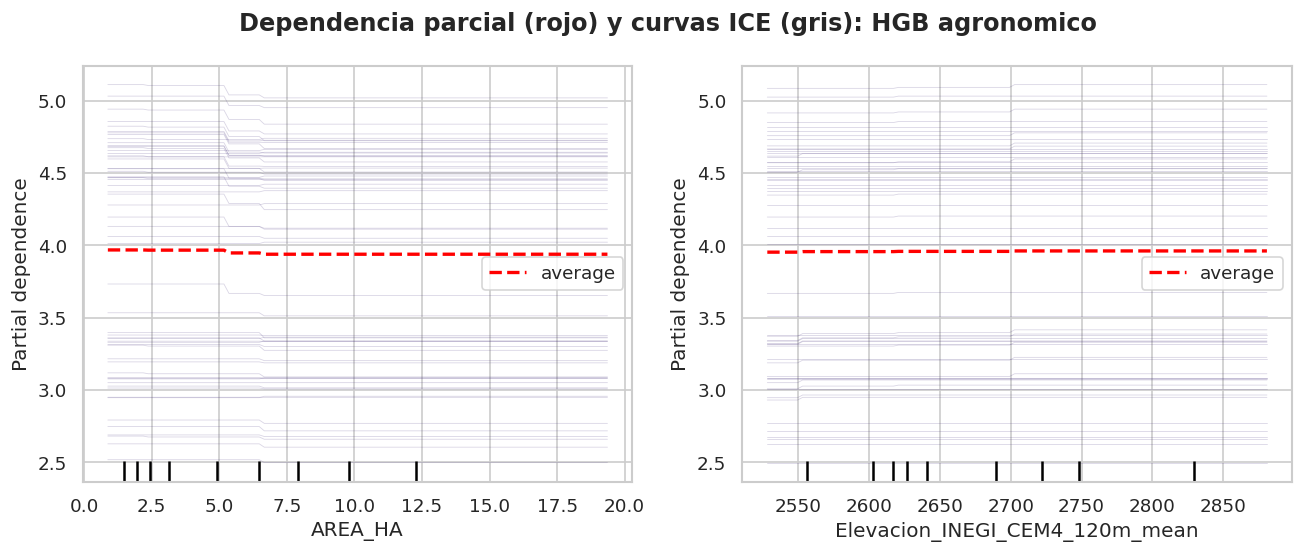

Lectura: curvas ICE paralelas indican un efecto aditivo consistente del modelo; NO prueban que el efecto sea causal (el area puede estar asociada a municipio, tipo de productor o ruido de pixeles de borde).


In [7]:
# ============================================================
# 7. DEPENDENCIA PARCIAL / ICE: AREA_HA Y ELEVACION
# ============================================================
pipe_pdp = construir_modelo('hgb').fit(X_full, y)
feats_pdp = [f for f in ['AREA_HA', col_elev] if f]

area = X_full['AREA_HA']
tramos = pd.cut(area, bins=[0, 4, 8, np.inf], labels=['< 4 ha', '4 - 8 ha', '> 8 ha'])
print("Parcelas por tramo de area:", tramos.value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, len(feats_pdp), figsize=(6.5 * len(feats_pdp), 4.5))
axes = np.atleast_1d(axes)
PartialDependenceDisplay.from_estimator(pipe_pdp, X_full, feats_pdp, kind='both', subsample=60,
                                        random_state=SEMILLA, ax=axes,
                                        ice_lines_kw={'alpha': 0.2}, pd_line_kw={'color': 'red', 'linewidth': 2})
fig.suptitle('Dependencia parcial (rojo) y curvas ICE (gris): HGB agronomico', fontweight='bold')
guardar_figura(fig, '05_pdp_ice_area_elevacion.png', 'reports')
plt.show()
print("Lectura: curvas ICE paralelas indican un efecto aditivo consistente del modelo; NO prueban que el efecto sea causal"
      " (el area puede estar asociada a municipio, tipo de productor o ruido de pixeles de borde).")

In [8]:
# ============================================================
# 8. PREGUNTAS GUIA: RESPUESTAS CONSTRUIDAS A PARTIR DE LOS NUMEROS
# ============================================================
def top_grupos(tipo, n=3, col='shap_media'):
    d = res_grp[res_grp['tipo'] == tipo].sort_values(col, ascending=False).head(n)
    return [(r.grupo, float(r.shap_media), float(r.shap_sd), float(r.perm_media), float(r.perm_sd)) for r in d.itertuples()]

def fmt(lista):
    return "; ".join(f"{g} (SHAP agrupado {s:.3f} +/- {sd:.3f}; Delta MAE por permutacion {p:+.4f} +/- {psd:.4f})" for g, s, sd, p, psd in lista)

resp = {}

# --- Q1: ¿Que indice es mas importante? ---
top_ind_shap = top_grupos('indice', 3, 'shap_media')
top_ind_perm = top_grupos('indice', 3, 'perm_media')
resp['q1_indice'] = {
    'top_por_shap': fmt(top_ind_shap),
    'top_por_permutacion_grupal': fmt(top_ind_perm),
    'coinciden_en_el_primero': top_ind_shap[0][0] == top_ind_perm[0][0],
    'advertencias': [
        "Orden preliminar: la variabilidad entre folds es comparable a las diferencias entre indices.",
        "Verificar la tabla de correlacion con ubicacion (posible proxy territorial).",
        "Los indices del mismo sensor comparten informacion; SHAP reparte importancia entre colineales."
    ],
}

# --- Q2: ¿Que variable climatica pesa mas? ---
top_cv = top_grupos('clima_variable', 3, 'shap_media')
top_cm = top_grupos('clima_mes', 3, 'shap_media')
resp['q2_clima'] = {
    'por_variable': fmt(top_cv), 'por_mes': fmt(top_cm),
    'advertencias': [
        "CHIRPS/CHIRTS tienen ~5 km: parcelas vecinas reciben valores casi identicos; poca variacion entre parcelas "
        "no implica que el clima no afecte el rendimiento.",
        "Las 21 columnas mensuales son muy colineales entre si (y con la elevacion); interpretar por variable, no por columna."
    ],
}

# --- Q3: ¿Que combinacion funciona mejor? (desde la Libreta 03) ---
df_res03 = cargar_csv('resultados_validacion.csv', '03_validacion')
df_abl03 = cargar_csv('resultados_ablacion.csv', '03_validacion')
mejor_modelo = {}
for esquema in df_res03['esquema'].unique():
    d = df_res03[df_res03['esquema'] == esquema].sort_values('MAE_fold_media')
    mejor_modelo[esquema] = f"{d.iloc[0]['modelo']} (MAE por fold {d.iloc[0]['MAE_fold_media']:.3f} +/- {d.iloc[0]['MAE_fold_sd']:.3f})"
abl_detectables = {}
for esquema in ['RepeatedKFold', 'LOGO_Municipio']:
    d = df_abl03[(df_abl03['esquema'] == esquema) & df_abl03['experimento'].str.startswith(('Sin_', 'Solo_'))]
    d = d[d['lectura'].isin(['mejora', 'empeora'])]
    abl_detectables[esquema] = [f"{r.experimento}: {r.lectura} ({r.delta_vs_completo:+.3f} +/- {r.delta_sd_folds:.3f})" for r in d.itertuples()] or ['ninguno']
resp['q3_combinacion'] = {
    'mejor_modelo_por_esquema': mejor_modelo,
    'ablacion_efectos_detectables': abl_detectables,
    'advertencias': [
        "Las diferencias pequenas frente a la variabilidad entre folds se describen como 'no detectables', no como 'iguales'.",
        "Con 138 parcelas el poder para detectar mejoras pequenas es bajo."
    ],
}

print(json.dumps(resp, ensure_ascii=False, indent=2))
with open(CARPETAS['04_shap'] / 'respuestas_preguntas_guia.json', 'w', encoding='utf-8') as f:
    json.dump(resp, f, ensure_ascii=False, indent=2)
print(f"\n[OK] Guardado: {CARPETAS['04_shap'] / 'respuestas_preguntas_guia.json'}")

[OK] Cargado: resultados_validacion.csv (15 filas x 10 cols)
[OK] Cargado: resultados_ablacion.csv (38 filas x 8 cols)
{
  "q1_indice": {
    "top_por_shap": "dswi4 (SHAP agrupado 0.055 +/- 0.030; Delta MAE por permutacion +0.0061 +/- 0.0143); dswi3 (SHAP agrupado 0.044 +/- 0.022; Delta MAE por permutacion +0.0062 +/- 0.0076); srndi (SHAP agrupado 0.043 +/- 0.018; Delta MAE por permutacion -0.0002 +/- 0.0128)",
    "top_por_permutacion_grupal": "ndti (SHAP agrupado 0.038 +/- 0.011; Delta MAE por permutacion +0.0066 +/- 0.0108); dswi3 (SHAP agrupado 0.044 +/- 0.022; Delta MAE por permutacion +0.0062 +/- 0.0076); dswi4 (SHAP agrupado 0.055 +/- 0.030; Delta MAE por permutacion +0.0061 +/- 0.0143)",
    "coinciden_en_el_primero": false,
    "advertencias": [
      "Orden preliminar: la variabilidad entre folds es comparable a las diferencias entre indices.",
      "Verificar la tabla de correlacion con ubicacion (posible proxy territorial).",
      "Los indices del mismo sensor comparten i

### 2. Modelo de entrega y artefactos para el dashboard

El modelo de entrega es el **ensamble 50/50** de KNN espacial y HGB final, ajustado con las 138 parcelas. Para cada una de las 59 parcelas a predecir se calcula:
- la **prediccion** y la de cada componente;
- un **intervalo empirico del 80 %** a partir de los errores fuera de muestra (RepeatedKFold si hay parcelas de referencia cercanas; LOGO si no las hay);
- las **3 parcelas vecinas** de entrenamiento, su distancia y su rendimiento;
- un indicador **"zona con referencias"** (distancia al vecino <= percentil 95 de las distancias entre vecinos de entrenamiento);
- las **3 variables que mas influyen** en la parte HGB de esa prediccion (SHAP local). El componente KNN se explica con las parcelas vecinas.

> Los errores fuera de muestra usados para los intervalos provienen de predicciones promediadas entre repeticiones (Libreta 03), por lo que el intervalo es **ligeramente optimista**. No es un intervalo de confianza estadistico formal.

In [9]:
# ============================================================
# 9. AJUSTE FINAL Y ARTEFACTOS PARA EL DASHBOARD
# ============================================================
R_TIERRA = 6371000.0

# ---------- Ajuste con las 138 parcelas ----------
modelo_knn = construir_modelo('knn').fit(coords, y)
modelo_hgb_final = construir_modelo('hgb_final', columnas_x=cols_feat_hgb_final).fit(X_hgb_final, y)

X_pred_final = pd.concat([df_prediccion[cols_feat_hgb_final], df_prediccion[COLS_COORDS]], axis=1)
pred_knn = modelo_knn.predict(df_prediccion[COLS_COORDS])
pred_hgb = modelo_hgb_final.predict(X_pred_final)
pred_ens = 0.5 * (pred_knn + pred_hgb)

# ---------- Intervalos empiricos (80 %) a partir de errores fuera de muestra ----------
df_oof = cargar_csv('predicciones_oof_todos_esquemas.csv', '03_validacion')
err_interp = np.abs(df_oof['RENDIMIENTO_T_HA'] - df_oof['RepeatedKFold__Ensamble_50_50'])
err_zona_nueva = np.abs(df_oof['RENDIMIENTO_T_HA'] - df_oof['LOGO_Municipio__Ensamble_50_50'])
q80_interp = float(np.quantile(err_interp, 0.80))
q80_nueva = float(np.quantile(err_zona_nueva, 0.80))
print(f"Semiancho del intervalo 80 %: interpolacion = +/-{q80_interp:.3f} t/ha | zona sin referencias (LOGO) = +/-{q80_nueva:.3f} t/ha")

# ---------- Vecinos y distancias (haversine, en metros) ----------
D_pred = haversine_distances(np.radians(df_prediccion[COLS_COORDS].values), np.radians(coords.values)) * R_TIERRA
D_tr = haversine_distances(np.radians(coords.values)) * R_TIERRA
np.fill_diagonal(D_tr, np.inf)
nn_train = D_tr.min(axis=1)
umbral_ref = float(np.quantile(nn_train, 0.95))
print(f"Distancia al vecino mas cercano entre parcelas de entrenamiento: mediana={np.median(nn_train):.0f} m, p95={umbral_ref:.0f} m")

orden = np.argsort(D_pred, axis=1)[:, :3]
filas = []
for i in range(len(df_prediccion)):
    fila = {'ID_POLIGONO': df_prediccion.loc[i, 'ID_POLIGONO'],
            'RENDIMIENTO_T_HA_PRED': float(pred_ens[i]),
            'pred_knn': float(pred_knn[i]), 'pred_hgb_final': float(pred_hgb[i]),
            'latitud': float(df_prediccion.loc[i, 'latitud']), 'longitud': float(df_prediccion.loc[i, 'longitud'])}
    if 'municipio' in df_prediccion.columns:
        fila['municipio'] = df_prediccion.loc[i, 'municipio']
    d1 = float(D_pred[i, orden[i, 0]])
    fila['dist_vecino_mas_cercano_m'] = d1
    fila['zona_con_referencias'] = bool(d1 <= umbral_ref)
    semiancho = q80_interp if fila['zona_con_referencias'] else q80_nueva
    fila['intervalo80_inf'] = float(pred_ens[i] - semiancho)
    fila['intervalo80_sup'] = float(pred_ens[i] + semiancho)
    fila['tipo_intervalo'] = 'interpolacion' if fila['zona_con_referencias'] else 'zona_sin_referencias'
    for r, j in enumerate(orden[i], start=1):
        fila[f'vecino{r}_id'] = ids.iloc[j]
        fila[f'vecino{r}_dist_m'] = float(D_pred[i, j])
        fila[f'vecino{r}_rend_t_ha'] = float(y.iloc[j])
    filas.append(fila)
df_dash = pd.DataFrame(filas)

# ---------- SHAP local de la parte HGB final ----------
try:
    ct = modelo_hgb_final.named_steps['ct']
    X_t = ct.transform(X_pred_final)
    nombres_t = [n.split('__', 1)[-1] for n in ct.get_feature_names_out()]
    sv = np.asarray(shap.TreeExplainer(modelo_hgb_final.named_steps['hgb']).shap_values(X_t))
    top3 = []
    for i in range(len(sv)):
        idx = np.argsort(-np.abs(sv[i]))[:3]
        top3.append("; ".join(f"{nombres_t[j]} ({sv[i, j]:+.2f})" for j in idx))
    df_dash['top3_variables_hgb_shap'] = top3
except Exception as e:
    print(f"[AVISO] No se pudo calcular el SHAP local ({type(e).__name__}: {e}); la columna se omite.")

# ---------- Guardar ----------
df_ref = pd.DataFrame({'ID_POLIGONO': ids, 'latitud': coords['latitud'], 'longitud': coords['longitud'],
                       'RENDIMIENTO_T_HA': y})
if 'municipio' in df_trabajo.columns:
    df_ref['municipio'] = df_trabajo['municipio'].values
df_entrega = df_dash[['ID_POLIGONO', 'RENDIMIENTO_T_HA_PRED']].copy()
df_entrega['RENDIMIENTO_T_HA_PRED'] = df_entrega['RENDIMIENTO_T_HA_PRED'].round(4)

guardar_csv(df_entrega, 'predicciones_59_ensamble.csv', '05_final')
guardar_csv(df_dash, 'dashboard_parcelas_prediccion.csv', '05_final')
guardar_csv(df_ref, 'dashboard_parcelas_referencia.csv', '05_final')
joblib.dump({'knn': modelo_knn, 'hgb_final': modelo_hgb_final, 'pesos': (0.5, 0.5),
             'q80_interpolacion': q80_interp, 'q80_zona_nueva': q80_nueva, 'umbral_referencia_m': umbral_ref,
             'columnas_features': cols_feat_hgb_final},
            CARPETAS['models'] / 'ensamble_knn_hgb_final.joblib')
print(f"[OK] Modelo guardado: {CARPETAS['models'] / 'ensamble_knn_hgb_final.joblib'}")

[OK] Cargado: predicciones_oof_todos_esquemas.csv (138 filas x 17 cols)
Semiancho del intervalo 80 %: interpolacion = +/-0.568 t/ha | zona sin referencias (LOGO) = +/-0.760 t/ha
Distancia al vecino mas cercano entre parcelas de entrenamiento: mediana=400 m, p95=2027 m
[OK] Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/05_final/predicciones_59_ensamble.csv
[OK] Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/05_final/dashboard_parcelas_prediccion.csv
[OK] Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/05_final/dashboard_parcelas_referencia.csv
[OK] Modelo guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/models/ensamble_knn_hgb_final.joblib


In [10]:
# ============================================================
# 10. CONTROLES DEL ARCHIVO DE PREDICCIONES
# ============================================================
controles = {}
controles['59_filas'] = len(df_entrega) == 59
controles['ids_unicos'] = bool(df_entrega['ID_POLIGONO'].is_unique)
controles['ids_son_los_de_prediccion'] = set(df_entrega['ID_POLIGONO']) == set(ids_prediccion)
controles['sin_nulos'] = bool(df_entrega['RENDIMIENTO_T_HA_PRED'].notna().all())
lo, hi = y.min() - 0.5, y.max() + 0.5
controles['dentro_de_rango_plausible'] = bool(df_entrega['RENDIMIENTO_T_HA_PRED'].between(lo, hi).all())
controles['max_diferencia_ensamble_vs_knn'] = float((df_dash['RENDIMIENTO_T_HA_PRED'] - df_dash['pred_knn']).abs().max())

for k, v in controles.items():
    etiqueta = '[OK]' if v is True else ('[ERROR]' if v is False else '-')
    print(f"   {etiqueta} {k}: {v}")
assert all(v for k, v in controles.items() if isinstance(v, bool)), "Algun control del CSV fallo; revisa antes de entregar."

print("\nDistribucion de las predicciones (t/ha) frente al entrenamiento:")
print(pd.DataFrame({'predicciones_59': df_entrega['RENDIMIENTO_T_HA_PRED'].describe(),
                    'entrenamiento_138': y.describe()}).round(3).to_string())
print(f"\nParcelas sin referencias cercanas (intervalo mas amplio): {int((~df_dash['zona_con_referencias']).sum())} de {len(df_dash)}")
print("[AVISO] Verifica en la plataforma del reto el formato EXACTO que exige el archivo de entrega (nombres de columnas, separador).")

resumen04 = {'version': '4.0-interpretabilidad', 'folds_importancia': n_folds, 'controles': controles,
             'q80_interpolacion': q80_interp, 'q80_zona_nueva': q80_nueva, 'umbral_referencia_m': umbral_ref}
with open(CARPETAS['04_shap'] / 'resumen_libreta04.json', 'w', encoding='utf-8') as f:
    json.dump(resumen04, f, ensure_ascii=False, indent=2, default=str)
print("\n[OK] Controles de validacion finalizados")

   [OK] 59_filas: True
   [OK] ids_unicos: True
   [OK] ids_son_los_de_prediccion: True
   [OK] sin_nulos: True
   [OK] dentro_de_rango_plausible: True
   - max_diferencia_ensamble_vs_knn: 0.1611258732442673

Distribucion de las predicciones (t/ha) frente al entrenamiento:
       predicciones_59  entrenamiento_138
count           59.000            138.000
mean             3.962              3.955
std              0.727              0.851
min              2.739              2.000
25%              3.167              3.200
50%              4.350              4.340
75%              4.560              4.550
max              5.058              5.590

Parcelas sin referencias cercanas (intervalo mas amplio): 0 de 59
[AVISO] Verifica en la plataforma del reto el formato EXACTO que exige el archivo de entrega (nombres de columnas, separador).

[OK] Controles de validacion finalizados


In [11]:
# ============================================================
# 11. EXPORTACION WEB: ARTEFACTOS PARA EL DASHBOARD
# ============================================================
print("1. GENERANDO BASE DE PREDICCIONES Y FOLDS (WEB_1)...")
municipios_todas = df_meta.set_index('ID_POLIGONO')['municipio'] if 'municipio' in df_meta.columns else df_meta.set_index('ID_POLIGONO')['estado']

# 1.1 Predicciones OOF para el set de Entrenamiento (138 parcelas)
kf_web = KFold(n_splits=5, shuffle=True, random_state=999)
df_train_web = pd.DataFrame(index=ids)
df_train_web['Tipo_Prediccion'] = 'OOF_Validacion'
df_train_web['Fold_ID'] = -1
df_train_web['Prediccion_Final'] = np.nan

for fold, (train_idx, test_idx) in enumerate(kf_web.split(X_hgb_final)):
    X_tr, X_te = X_hgb_final.iloc[train_idx], X_hgb_final.iloc[test_idx]
    y_tr = y.iloc[train_idx]

    # Entrenar componentes en N-1 folds
    knn_fold = construir_modelo('knn').fit(coords.iloc[train_idx], y_tr)
    hgb_fold = construir_modelo('hgb_final', columnas_x=cols_feat_hgb_final).fit(X_tr, y_tr)

    # Predecir en el fold oculto
    p_knn = knn_fold.predict(coords.iloc[test_idx])
    p_hgb = hgb_fold.predict(X_te)

    df_train_web.iloc[test_idx, df_train_web.columns.get_loc('Fold_ID')] = fold + 1
    df_train_web.iloc[test_idx, df_train_web.columns.get_loc('Prediccion_Final')] = 0.5 * (p_knn + p_hgb)

# 1.2 Predicciones Finales (59 parcelas)
df_test_web = pd.DataFrame(index=df_prediccion['ID_POLIGONO'])
df_test_web['Tipo_Prediccion'] = 'Prediccion_Final_Ciega'
df_test_web['Fold_ID'] = np.nan
df_test_web['Prediccion_Final'] = pred_ens

# Unir todo y guardar
df_web_total = pd.concat([df_train_web, df_test_web])
df_web_total = df_web_total.join(municipios_todas, how='left').rename(columns={municipios_todas.name: 'Municipio'})
df_web_total.index.name = 'ID_POLIGONO'
ruta_web1 = guardar_csv(df_web_total.reset_index(), 'WEB_1_Predicciones_y_Grupos.csv', 'artifacts')

print("\n2. CUADRANDO LA MATEMATICA SHAP (WEB_2)...")
ct = modelo_hgb_final.named_steps['ct']
hgb_model = modelo_hgb_final.named_steps['hgb']

# Transformar datos con el pipeline ajustado
X_prep = ct.transform(X_hgb_final)
nombres_features = [n.split('__', 1)[-1] for n in ct.get_feature_names_out()]
X_prep_df = pd.DataFrame(X_prep, columns=nombres_features, index=ids)

# Extraer valores SHAP usando TreeExplainer
explainer = shap.TreeExplainer(hgb_model)
shap_values = explainer.shap_values(X_prep_df)

base_value = explainer.expected_value
if isinstance(base_value, np.ndarray):
    base_value = base_value[0]

shap_df = pd.DataFrame(shap_values, columns=nombres_features, index=ids)
prediccion_hgb_exacta = base_value + shap_df.sum(axis=1)

shap_export = shap_df.copy()
shap_export.insert(0, 'Base_Value', base_value)
shap_export.insert(1, 'Prediccion_Explicada_HGB', prediccion_hgb_exacta)
shap_export.index.name = 'ID_POLIGONO'
ruta_web2 = guardar_csv(shap_export.reset_index(), 'WEB_2_SHAP_Explicaciones.csv', 'artifacts')

print("\n3. DICCIONARIO DE METADATOS Y CAPAS (WEB_3)...")
metadatos = []
for col in X_hgb_final.columns:
    fuente, unidad, agregacion, fecha = "Calculada / Derivada", "Adimensional", "Constante / Estacional", "General 2025"

    if 'BASICO' in col.upper():
        fuente = "Sentinel-2 / Landsat"
    elif 'PRO' in col.upper() or 'FAPAR' in col.upper() or 'NDVI' in col.upper() or 'LAI' in col.upper() or 'EVI' in col.upper():
        fuente = "Sentinel-2 / Planet"
    elif 'PREC' in col.upper():
        fuente, unidad = "CHIRPS", "Milimetros (mm)"
    elif 'TMAX' in col.upper() or 'TMIN' in col.upper():
        fuente, unidad = "CHIRTS", "Grados Centigrados (C)"
    elif 'LATITUD' in col.upper() or 'LONGITUD' in col.upper():
        fuente, unidad = "Geometria Espacial", "Grados Decimales"
    elif 'AREA_HA' in col.upper():
        fuente, unidad = "Shapefile", "Hectareas (ha)"
    elif 'ELEVACION' in col.upper() or 'PENDIENTE' in col.upper():
        fuente, unidad = "INEGI CEM 4.0", "Metros / Grados"

    mes_match = re.search(r'2025_(\d{2})', col)
    if mes_match:
        meses = {'04':'Abril', '05':'Mayo', '06':'Junio', '07':'Julio', '08':'Agosto', '09':'Septiembre', '10':'Octubre'}
        fecha = f"{meses.get(mes_match.group(1), mes_match.group(1))} 2025"
        agregacion = "Mensual"

    metadatos.append({'Capa_ID': col, 'Fuente': fuente, 'Unidad': unidad, 'Agregacion': agregacion, 'Fecha_Mes': fecha})

df_metadatos = pd.DataFrame(metadatos)
ruta_web3 = guardar_csv(df_metadatos, 'WEB_3_Diccionario_Metadatos.csv', 'artifacts')

print("\n[OK] LIBRETA 04 COMPLETADA - Todos los archivos de integracion web estan listos en 'artifacts'")

1. GENERANDO BASE DE PREDICCIONES Y FOLDS (WEB_1)...
[OK] Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/artifacts/WEB_1_Predicciones_y_Grupos.csv

2. CUADRANDO LA MATEMATICA SHAP (WEB_2)...
[OK] Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/artifacts/WEB_2_SHAP_Explicaciones.csv

3. DICCIONARIO DE METADATOS Y CAPAS (WEB_3)...
[OK] Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/artifacts/WEB_3_Diccionario_Metadatos.csv

[OK] LIBRETA 04 COMPLETADA - Todos los archivos de integracion web estan listos en 'artifacts'
